<a href="https://colab.research.google.com/github/FreddyForero1988/skills-getting-started-with-github-copilot/blob/main/Proyecto_estad%C3%ADsticas_de_Youtube_IV_FreddyForero.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PARTE 1: Avances I (datos)

Descarga e inspección

In [5]:
  !pip -q install kagglehub vaderSentiment

  import kagglehub, os, glob
  path = kagglehub.dataset_download("advaypatil/youtube-statistics")
  print("Ruta:", path)
  for f in glob.glob(path + "/**/*", recursive=True):
      if os.path.isfile(f):
          print(f, "|", round(os.path.getsize(f) / 1e6, 2), "MB")

100%|██████████| 1.64M/1.64M [00:00<00:00, 29.4MB/s]

Extracting files...


Ruta: /root/.cache/kagglehub/datasets/advaypatil/youtube-statistics/versions/1
/root/.cache/kagglehub/datasets/advaypatil/youtube-statistics/versions/1/videos-stats.csv | 0.23 MB
/root/.cache/kagglehub/datasets/advaypatil/youtube-statistics/versions/1/comments.csv | 4.05 MB


Carga, normalización y calidad

In [6]:
import pandas as pd, numpy as np, re
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 50)

def leer(f):
    try:
        return pd.read_csv(f)
    except UnicodeDecodeError:
        return pd.read_csv(f, encoding="latin-1")

def norm(df):
    df = df.loc[:, ~df.columns.str.contains("^Unnamed")].copy()
    df.columns = df.columns.str.strip().str.lower().str.replace(r"\s+", "_", regex=True)
    return df

f_vid = glob.glob(path + "/**/videos-stats.csv", recursive=True)[0]
f_com = glob.glob(path + "/**/comments.csv", recursive=True)[0]
videos = norm(leer(f_vid)).rename(columns={"comments": "comment_count", "likes": "video_likes"})
comments = norm(leer(f_com)).rename(columns={"likes": "comment_likes", "comment": "comment_text"})

print("Columnas videos   :", list(videos.columns))
print("Columnas comentarios:", list(comments.columns))
print("VIDEOS:", videos.shape, "| COMENTARIOS:", comments.shape)
display(videos.head(3)); display(comments.head(3))

def calidad(df, nombre):
    print(f"\n===== {nombre} =====")
    display(pd.DataFrame({"tipo": df.dtypes, "nulos": df.isna().sum(),
                          "%nulos": (df.isna().mean() * 100).round(2), "unicos": df.nunique()}))
    print("Filas duplicadas:", df.duplicated().sum())

calidad(videos, "VIDEOS"); calidad(comments, "COMENTARIOS")

# Limpieza
for c in ["views", "video_likes", "comment_count"]:
    videos[c] = pd.to_numeric(videos[c], errors="coerce")
videos = videos.dropna(subset=["video_id", "views"]).drop_duplicates(subset="video_id")
comments["comment_likes"] = pd.to_numeric(comments["comment_likes"], errors="coerce").fillna(0)
comments = comments.dropna(subset=["video_id", "comment_text"]).drop_duplicates()
comments["comment_text"] = comments["comment_text"].astype(str)

print("\nValores de Sentiment:"); print(comments["sentiment"].value_counts(dropna=False).sort_index())

# Cobertura
print(f"\nVideos: {len(videos)} | con comentarios: {comments['video_id'].nunique()} | en ambos: "
      f"{len(set(videos['video_id']) & set(comments['video_id']))}")
cpv = comments.groupby("video_id").size()
print("\nComentarios por video:"); print(cpv.describe())
print("\nKeywords:", videos["keyword"].nunique()); print(videos["keyword"].value_counts().head(10))

Columnas videos   : ['title', 'video_id', 'published_at', 'keyword', 'video_likes', 'comment_count', 'views']
Columnas comentarios: ['video_id', 'comment_text', 'comment_likes', 'sentiment']
VIDEOS: (1881, 7) | COMENTARIOS: (18409, 4)


,title,video_id,published_at,keyword,video_likes,comment_count,views
0,Apple Pay Is Killing the Physical Wallet After...,wAZZ-UWGVHI,2022-08-23,tech,3407.0,672.0,135612.0
1,The most EXPENSIVE thing I own.,b3x28s61q3c,2022-08-24,tech,76779.0,4306.0,1758063.0
2,My New House Gaming Setup is SICK!,4mgePWWCAmA,2022-08-23,tech,63825.0,3338.0,1564007.0


,video_id,comment_text,comment_likes,sentiment
0,wAZZ-UWGVHI,Let's not forget that Apple Pay in 2014 requir...,95.0,1.0
1,wAZZ-UWGVHI,Here in NZ 50% of retailers don’t even have co...,19.0,0.0
2,wAZZ-UWGVHI,I will forever acknowledge this channel with t...,161.0,2.0



===== VIDEOS =====


,tipo,nulos,%nulos,unicos
title,object,0,0.00,1854
video_id,object,0,0.00,1869
published_at,object,0,0.00,757
keyword,object,0,0.00,41
video_likes,float64,2,0.11,1827
comment_count,float64,2,0.11,1372
views,float64,2,0.11,1868


Filas duplicadas: 0

===== COMENTARIOS =====


,tipo,nulos,%nulos,unicos
video_id,object,0,0.00,1869
comment_text,object,1,0.01,17994
comment_likes,float64,0,0.00,2539
sentiment,float64,0,0.00,3


Filas duplicadas: 148

Valores de Sentiment:
sentiment
0.0     2332
1.0     4610
2.0    11318
Name: count, dtype: int64

Videos: 1867 | con comentarios: 1869 | en ambos: 1867

Comentarios por video:
count    1869.000000
mean        9.769930
std         1.162188
min         1.000000
25%        10.000000
50%        10.000000
75%        10.000000
max        18.000000
dtype: float64

Keywords: 41
keyword
crypto              50
tutorial            50
cnn                 50
physics             50
marvel              50
data science        50
game development    50
trolling            50
interview           50
mrbeast             50
Name: count, dtype: int64


Tabla a nivel de video, VADER y variables derivadas

In [7]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.metrics import cohen_kappa_score, confusion_matrix

sia = SentimentIntensityAnalyzer()
comments["vader"] = comments["comment_text"].map(lambda t: sia.polarity_scores(t)["compound"])
comments["clen"] = comments["comment_text"].str.len()

# Concordancia entre la etiqueta del dataset y VADER (supone 0=neg, 1=neu, 2=pos)
vader_cls = np.where(comments["vader"] >= 0.05, 2, np.where(comments["vader"] <= -0.05, 0, 1))
lab = pd.to_numeric(comments["sentiment"], errors="coerce")
ok = lab.notna()
print("Accuracy de acuerdo VADER vs etiqueta:", (vader_cls[ok] == lab[ok]).mean().round(3))
print("Cohen's kappa:", round(cohen_kappa_score(lab[ok].astype(int), vader_cls[ok]), 3))
print(pd.DataFrame(confusion_matrix(lab[ok].astype(int), vader_cls[ok]),
                   index=["etq_0", "etq_1", "etq_2"], columns=["vader_0", "vader_1", "vader_2"]))

comments["sent_num"] = lab
agg = comments.groupby("video_id").agg(
    n_comments=("comment_text", "size"),
    text=("comment_text", lambda s: " ".join(s)),
    mean_clen=("clen", "mean"),
    mean_cl_likes=("comment_likes", "mean"),
    mean_vader=("vader", "mean"),
    std_vader=("vader", "std"),
    mean_sent=("sent_num", "mean"),
    pct_neg=("sent_num", lambda s: (s == 0).mean()),
    pct_pos=("sent_num", lambda s: (s == 2).mean()),
).reset_index()

df = videos.merge(agg, on="video_id", how="inner")
df["published_at"] = pd.to_datetime(df["published_at"], errors="coerce", utc=True)
df["age_days"] = (df["published_at"].max() - df["published_at"]).dt.days
df["title_len"] = df["title"].astype(str).str.len()
df["log_views"] = np.log1p(df["views"])
df["log_likes"] = np.log1p(df["video_likes"])
df["log_comment_count"] = np.log1p(df["comment_count"])
df["engagement"] = (df["video_likes"].fillna(0) + df["comment_count"].fillna(0)) / df["views"].clip(lower=1)

print("Dataset a nivel de video:", df.shape)
df.to_csv("video_level.csv", index=False)

# (Recomendado) guardar en Drive para no perderlo si se reinicia Colab
# from google.colab import drive; drive.mount('/content/drive')
# df.to_csv("/content/drive/MyDrive/video_level.csv", index=False)

Accuracy de acuerdo VADER vs etiqueta: 0.715
Cohen's kappa: 0.428
       vader_0  vader_1  vader_2
etq_0     1210      321      801
etq_1      782     1614     2214
etq_2      514      566    10238


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


Dataset a nivel de video: (1867, 22)


Variables objetivo y análisis estadísticos no triviales

views          skew=   29.46  kurt=  1027.47 | log: skew=0.05
video_likes    skew=   11.61  kurt=   180.00 | log: skew=nan
comment_count  skew=   12.49  kurt=   197.09 | log: skew=nan


/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_stats_py.py:1158: RuntimeWarning: invalid value encountered in subtract
  a_zero_mean = a - mean


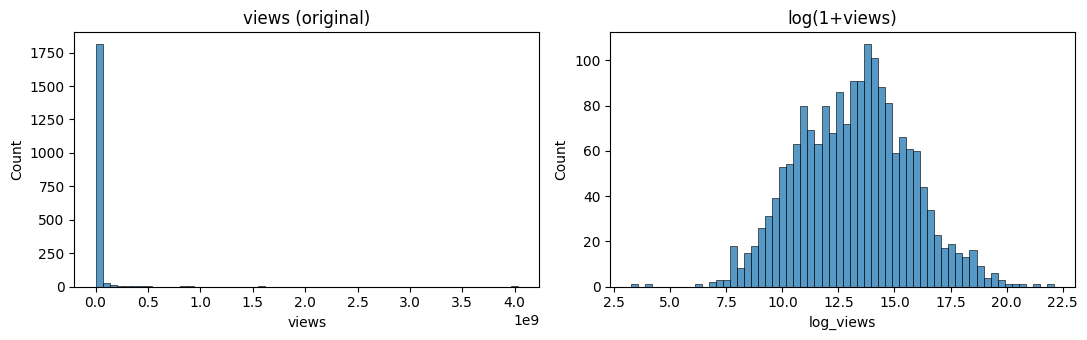

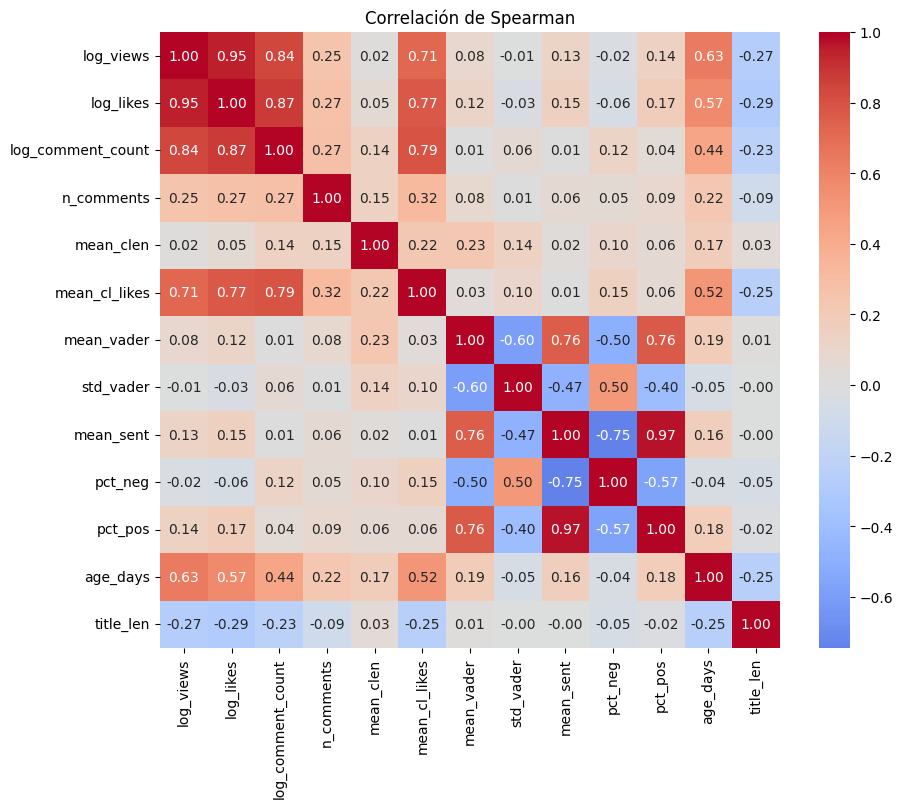

Spearman mean_vader     vs log_views: rho=+0.083  p=0.0003281
Spearman mean_sent      vs log_views: rho=+0.126  p=5.151e-08
Spearman pct_neg        vs log_views: rho=-0.023  p=0.3161
Spearman pct_pos        vs log_views: rho=+0.145  p=3.093e-10
Spearman mean_cl_likes  vs log_views: rho=+0.714  p=3.798e-291
Spearman mean_clen      vs log_views: rho=+0.018  p=0.4455
Spearman age_days       vs log_views: rho=+0.634  p=1.767e-210

Kruskal-Wallis log_views ~ keyword: H=591.9, p=2.31e-99, eta2_H=0.302
IC 95% bootstrap rho(mean_sent, log_views): [0.083 0.169]
Spearman log_likes vs log_views: 0.944


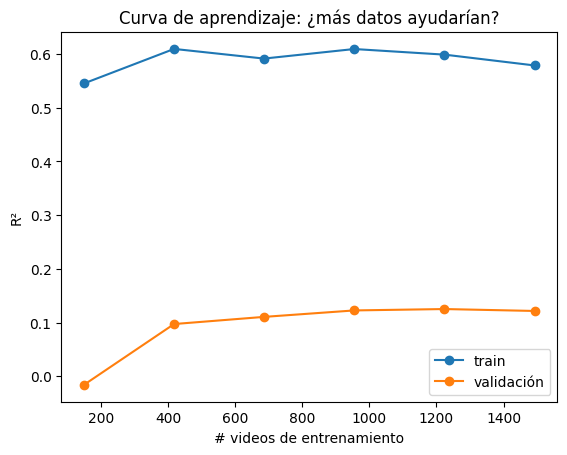

In [8]:
from scipy import stats

# 1) Asimetría y curtosis, antes y después del log
for c in ["views", "video_likes", "comment_count"]:
    x = df[c].dropna()
    print(f"{c:14s} skew={stats.skew(x):8.2f}  kurt={stats.kurtosis(x):9.2f} | log: skew={stats.skew(np.log1p(x)):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(df["views"], bins=60, ax=ax[0]).set_title("views (original)")
sns.histplot(df["log_views"], bins=60, ax=ax[1]).set_title("log(1+views)")
plt.tight_layout(); plt.show()

# 2) Correlaciones de Spearman
cols = ["log_views", "log_likes", "log_comment_count", "n_comments", "mean_clen", "mean_cl_likes",
        "mean_vader", "std_vader", "mean_sent", "pct_neg", "pct_pos", "age_days", "title_len"]
corr = df[cols].corr(method="spearman")
plt.figure(figsize=(10, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación de Spearman"); plt.show()

# 3) Sentimiento de los comentarios vs vistas (test + p-valor)
for c in ["mean_vader", "mean_sent", "pct_neg", "pct_pos", "mean_cl_likes", "mean_clen", "age_days"]:
    rho, p = stats.spearmanr(df[c], df["log_views"], nan_policy="omit")
    print(f"Spearman {c:14s} vs log_views: rho={rho:+.3f}  p={p:.4g}")

# 4) Desempeño por keyword (Kruskal-Wallis + tamaño de efecto eta^2_H)
grupos = [g["log_views"].values for _, g in df.groupby("keyword") if len(g) >= 5]
H, p = stats.kruskal(*grupos)
k, n = len(grupos), sum(len(g) for g in grupos)
print(f"\nKruskal-Wallis log_views ~ keyword: H={H:.1f}, p={p:.4g}, eta2_H={(H - k + 1) / (n - k):.3f}")

# 5) IC 95% bootstrap de rho(sentimiento medio, log_views)
rng = np.random.default_rng(42)
x, y = df["mean_sent"].values, df["log_views"].values
m = ~(np.isnan(x) | np.isnan(y)); x, y = x[m], y[m]
bs = []
for _ in range(1000):
    i = rng.integers(0, len(x), len(x))
    bs.append(stats.spearmanr(x[i], y[i])[0])
print("IC 95% bootstrap rho(mean_sent, log_views):", np.percentile(bs, [2.5, 97.5]).round(3))

# 6) Likes del video vs vistas (muestra por qué se excluyen como predictor: fuga)
print("Spearman log_likes vs log_views:", round(stats.spearmanr(df["log_likes"], df["log_views"], nan_policy="omit")[0], 3))

# 7) ¿Son suficientes los datos? Curva de aprendizaje con TF-IDF + Ridge
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import learning_curve
pipe = make_pipeline(TfidfVectorizer(max_features=15000, min_df=3, stop_words="english"), Ridge(alpha=3))
sizes, tr, va = learning_curve(pipe, df["text"], df["log_views"], cv=5,
                               train_sizes=np.linspace(0.1, 1, 6), scoring="r2", n_jobs=-1)
plt.plot(sizes, tr.mean(1), "o-", label="train"); plt.plot(sizes, va.mean(1), "o-", label="validación")
plt.xlabel("# videos de entrenamiento"); plt.ylabel("R²"); plt.legend()
plt.title("Curva de aprendizaje: ¿más datos ayudarían?"); plt.show()

PARTE 2: Avances II (modelo)

Preparación y partición

In [9]:
import pandas as pd, numpy as np, re
from sklearn.model_selection import train_test_split, KFold, cross_validate

df = pd.read_csv("video_level.csv")   # o desde Drive

def limpiar(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t)
    t = re.sub(r"[^a-z\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

df["text_clean"] = df["text"].map(limpiar)
df["alto"] = (df["views"] > df["views"].median()).astype(int)

NUM = ["n_comments", "mean_clen", "mean_cl_likes", "mean_vader", "std_vader",
       "mean_sent", "pct_neg", "pct_pos", "age_days", "title_len"]
CAT = ["keyword"]
df[NUM] = df[NUM].fillna(df[NUM].median())
df[CAT] = df[CAT].astype(str)

X = df[["text_clean", "log_likes"] + NUM + CAT]
X["log_likes"] = X["log_likes"].fillna(X["log_likes"].median())
y_reg, y_clf = df["log_views"], df["alto"]
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf)
print(X_tr.shape, X_te.shape)

(1493, 13) (374, 13)


/tmp/ipykernel_13388/895615627.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X["log_likes"] = X["log_likes"].fillna(X["log_likes"].median())


In [10]:
# 1) Diagnóstico: ¿qué columnas tienen valores no finitos?
num_cols = X.select_dtypes(include=[np.number]).columns
print("No finitos por columna:")
print((~np.isfinite(X[num_cols])).sum()[lambda s: s > 0])
print("Objetivo log_views no finitos:", (~np.isfinite(y_reg)).sum())
print(df.loc[~np.isfinite(df["log_likes"]), ["video_likes", "views"]].head())

# 2) Corrección: infinitos -> NaN -> mediana
X = X.copy()
X[num_cols] = X[num_cols].replace([np.inf, -np.inf], np.nan)
X[num_cols] = X[num_cols].fillna(X[num_cols].median())

# 3) Repetir la partición (mismo random_state, mismas filas)
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf)
print("Listo:", X_tr.shape, X_te.shape, "| no finitos en train:", (~np.isfinite(X_tr[num_cols])).sum().sum())

No finitos por columna:
log_likes    6
dtype: int64
Objetivo log_views no finitos: 0
      video_likes      views
242          -1.0   676300.0
265          -1.0    12332.0
581          -1.0  6515548.0
1012         -1.0    27451.0
1668         -1.0   553892.0
Listo: (1493, 13) (374, 13) | no finitos en train: 0


Comparación de modelos (regresión, validación cruzada)

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

tfidf = lambda: TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3,
                                stop_words="english", sublinear_tf=True)

def prep(usar_texto=True, usar_meta=True, svd=None, con_likes=False):
    t = []
    if usar_texto:
        pasos = [("tf", tfidf())] + ([("svd", TruncatedSVD(svd, random_state=42))] if svd else [])
        t.append(("txt", Pipeline(pasos), "text_clean"))
    if usar_meta:
        t += [("num", StandardScaler(), NUM + (["log_likes"] if con_likes else [])),
              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)]
    return ColumnTransformer(t)

modelos = {
    "0. Baseline (media)":               Pipeline([("p", prep(False, True)), ("m", DummyRegressor())]),
    "1. Solo metadatos + Ridge":         Pipeline([("p", prep(False, True)), ("m", Ridge(alpha=1))]),
    "2. Solo texto TF-IDF + Ridge":      Pipeline([("p", prep(True, False)), ("m", Ridge(alpha=3))]),
    "3. TF-IDF + meta + Ridge":          Pipeline([("p", prep(True, True)),  ("m", Ridge(alpha=3))]),
    "4. SVD(100) + meta + RandomForest": Pipeline([("p", prep(True, True, 100)), ("m", RandomForestRegressor(300, n_jobs=-1, random_state=42))]),
    "5. SVD(100) + meta + HistGB":       Pipeline([("p", prep(True, True, 100)), ("m", HistGradientBoostingRegressor(random_state=42))]),
    "REF. TF-IDF + meta + likes (fuga)": Pipeline([("p", prep(True, True, con_likes=True)), ("m", Ridge(alpha=3))]),
}

cv = KFold(5, shuffle=True, random_state=42)
filas = []
for nombre, m in modelos.items():
    r = cross_validate(m, X_tr, yr_tr, cv=cv, n_jobs=-1,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
    filas.append({"modelo": nombre, "R2": r["test_r2"].mean(), "R2_std": r["test_r2"].std(),
                  "RMSE": -r["test_rmse"].mean(), "MAE": -r["test_mae"].mean()})
    print("listo:", nombre)
res = pd.DataFrame(filas).sort_values("RMSE").round(4)
display(res)

listo: 0. Baseline (media)
listo: 1. Solo metadatos + Ridge
listo: 2. Solo texto TF-IDF + Ridge
listo: 3. TF-IDF + meta + Ridge
listo: 4. SVD(100) + meta + RandomForest
listo: 5. SVD(100) + meta + HistGB
listo: REF. TF-IDF + meta + likes (fuga)


,modelo,R2,R2_std,RMSE,MAE
6,REF. TF-IDF + meta + likes (fuga),0.9416,0.0032,0.6010,0.4494
5,5. SVD(100) + meta + HistGB,0.7219,0.0344,1.3071,0.9640
4,4. SVD(100) + meta + RandomForest,0.7151,0.0313,1.3234,0.9923
3,3. TF-IDF + meta + Ridge,0.4331,0.1368,1.8673,1.3355
1,1. Solo metadatos + Ridge,0.3778,0.1562,1.9552,1.3978
2,2. Solo texto TF-IDF + Ridge,0.2762,0.0076,2.1169,1.6793
0,0. Baseline (media),-0.0028,0.0032,2.4916,2.0079


Ajuste de hiperparámetros y evaluación final


In [12]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

pipe = Pipeline([("p", prep(True, True)), ("m", Ridge())])
gs = GridSearchCV(pipe, {"m__alpha": [0.3, 1, 3, 10, 30], "p__txt__tf__ngram_range": [(1, 1), (1, 2)]},
                  cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_tr, yr_tr)
print("Mejores parámetros:", gs.best_params_, "| RMSE CV:", round(-gs.best_score_, 4))

pred = gs.predict(X_te)
rmse = mean_squared_error(yr_te, pred) ** 0.5
print(f"TEST -> R2={r2_score(yr_te, pred):.3f}  RMSE={rmse:.3f}  MAE={mean_absolute_error(yr_te, pred):.3f}")
print(f"Error típico multiplicativo en vistas: x{np.exp(rmse):.2f}")

# Términos más asociados a más/menos vistas
tf = gs.best_estimator_.named_steps["p"].named_transformers_["txt"].named_steps["tf"]
terms = np.array(tf.get_feature_names_out())
coef = gs.best_estimator_.named_steps["m"].coef_[:len(terms)]
print("\n+ vistas:", terms[np.argsort(coef)[-15:]][::-1])
print("- vistas:", terms[np.argsort(coef)[:15]])

Mejores parámetros: {'m__alpha': 1, 'p__txt__tf__ngram_range': (1, 2)} | RMSE CV: 1.8345
TEST -> R2=0.562  RMSE=1.625  MAE=1.271
Error típico multiplicativo en vistas: x5.08

+ vistas: ['zoom' 'bed' 'did' 'imagine' 'satisfying' 'sica' 'cube' 'que' 'literally'
 'makes' 'guy' 'die' 'nostalgic' 'actually' 'canci']
- vistas: ['great video' 'great' 'thanks' 'destroyed' 'channel' 'lady' 'sir' 'vid'
 'wow' 'google' 'game' 'viewing' 'happen' 'goal' 'look']


Clasificación (alto/bajo desempeño)

,modelo,accuracy,F1_macro,AUC
0,Baseline,0.5003,0.3335,0.5000
1,TF-IDF + meta + LogReg,0.8265,0.8263,0.9041
2,SVD + meta + HistGB,0.8573,0.8573,0.9311


              precision    recall  f1-score   support

           0       0.77      0.82      0.79       187
           1       0.81      0.75      0.78       187

    accuracy                           0.79       374
   macro avg       0.79      0.79      0.79       374
weighted avg       0.79      0.79      0.79       374



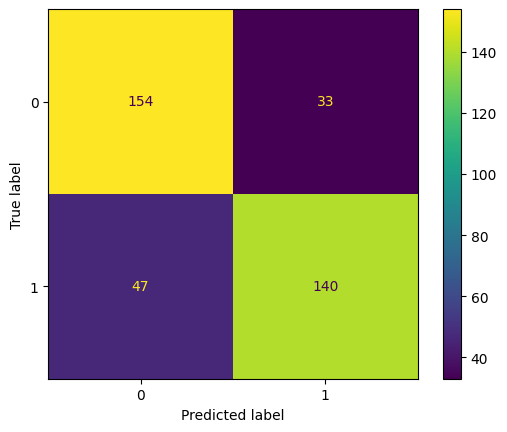

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

clfs = {
    "Baseline": Pipeline([("p", prep(False, True)), ("m", DummyClassifier(strategy="prior"))]),
    "TF-IDF + meta + LogReg": Pipeline([("p", prep(True, True)), ("m", LogisticRegression(max_iter=2000, C=1))]),
    "SVD + meta + HistGB": Pipeline([("p", prep(True, True, 100)), ("m", HistGradientBoostingClassifier(random_state=42))]),
}
scv = StratifiedKFold(5, shuffle=True, random_state=42)
filas = []
for n, m in clfs.items():
    r = cross_validate(m, X_tr, yc_tr, cv=scv, n_jobs=-1, scoring=["accuracy", "f1_macro", "roc_auc"])
    filas.append({"modelo": n, "accuracy": r["test_accuracy"].mean(),
                  "F1_macro": r["test_f1_macro"].mean(), "AUC": r["test_roc_auc"].mean()})
display(pd.DataFrame(filas).round(4))

final = clfs["TF-IDF + meta + LogReg"].fit(X_tr, yc_tr)
print(classification_report(yc_te, final.predict(X_te)))
ConfusionMatrixDisplay.from_estimator(final, X_te, yc_te); plt.show()

In [14]:
# Celda 9: HistGB en prueba + ablación
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def evalua(nombre, num_quitar=()):
    global NUM
    NUM_bak = NUM[:]
    NUM = [c for c in NUM_bak if c not in num_quitar]
    m = Pipeline([("p", prep(True, True, 100)), ("m", HistGradientBoostingRegressor(random_state=42))])
    r = cross_validate(m, X_tr, yr_tr, cv=cv, n_jobs=-1, scoring=["r2", "neg_root_mean_squared_error"])
    m.fit(X_tr, yr_tr); p = m.predict(X_te)
    print(f"{nombre:38s} CV R2={r['test_r2'].mean():.3f} | TEST R2={r2_score(yr_te,p):.3f} "
          f"RMSE={mean_squared_error(yr_te,p)**0.5:.3f} MAE={mean_absolute_error(yr_te,p):.3f}")
    NUM = NUM_bak
evalua("HistGB completo")
evalua("sin mean_cl_likes", ("mean_cl_likes",))
evalua("sin age_days", ("age_days",))
evalua("sin ambos", ("mean_cl_likes", "age_days"))

HistGB completo                        CV R2=0.722 | TEST R2=0.733 RMSE=1.270 MAE=0.947
sin mean_cl_likes                      CV R2=0.616 | TEST R2=0.643 RMSE=1.468 MAE=1.112
sin age_days                           CV R2=0.630 | TEST R2=0.636 RMSE=1.482 MAE=1.136
sin ambos                              CV R2=0.414 | TEST R2=0.450 RMSE=1.822 MAE=1.434


# Semana 9 - Proyecto estadísticas de Youtube Avances III

In [15]:
!pip -q install sentence-transformers langdetect transformers

import torch, numpy as np, pandas as pd
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0

def idioma(t):
    try: return detect(t)
    except Exception: return "unk"

comments["lang"] = comments["comment_text"].map(idioma)   # ~1-3 min
print(comments["lang"].value_counts(normalize=True).head(8).round(3))

pct_en = comments.groupby("video_id")["lang"].apply(lambda s: (s == "en").mean()).rename("pct_en")
print("\n% de comentarios en inglés por video:"); print(pct_en.describe().round(3))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
lang
en     0.887
es     0.022
pt     0.020
fr     0.007
de     0.006
vi     0.006
id     0.004
unk    0.004
Name: proportion, dtype: float64

% de comentarios en inglés por video:
count    1869.000
mean        0.882
std         0.263
min         0.000
25%         0.900
50%         1.000
75%         1.000
max         1.000
Name: pct_en, dtype: float64


In [16]:
from sentence_transformers import SentenceTransformer
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", dev)

st = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2", device=dev)
emb = st.encode(comments["comment_text"].tolist(), batch_size=128,
                show_progress_bar=True, normalize_embeddings=True)
print("Embeddings:", emb.shape)
np.save("emb_comments.npy", emb)       # opcional: copiar a Drive para no recalcular

EMB = [f"e{i}" for i in range(emb.shape[1])]
vid_emb = (pd.DataFrame(emb, columns=EMB)
             .assign(video_id=comments["video_id"].values)
             .groupby("video_id").mean())          # promedio de embeddings por video
print("Embeddings a nivel de video:", vid_emb.shape)

Dispositivo: cpu


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/143 [00:00<?, ?it/s]

Embeddings: (18260, 384)
Embeddings a nivel de video: (1869, 384)


In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, GroupKFold
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from scipy import stats

lab = pd.to_numeric(comments["sentiment"], errors="coerce")
ok = lab.notna().values
y = lab[ok].astype(int).values
grupos = comments.loc[ok, "video_id"].values

# Predicciones fuera de muestra: ningún comentario es predicho por un modelo que vio su video
clf = LogisticRegression(max_iter=1000, C=2)
oof = cross_val_predict(clf, emb[ok], y, cv=GroupKFold(5), groups=grupos,
                        method="predict_proba", n_jobs=-1)
P3 = np.zeros((len(comments), 3)); P3[ok] = oof
if (~ok).any():                                          # por si hubiera comentarios sin etiqueta
    P3[~ok] = clf.fit(emb[ok], y).predict_proba(emb[~ok])

comments["tr_score"] = P3[:, 2] - P3[:, 0]               # positivo - negativo
comments["tr_cls"] = P3.argmax(1)                        # 0=neg, 1=neu, 2=pos
np.save("sent_transformer.npy", P3)

pred = comments.loc[ok, "tr_cls"].values
print("Sentimiento sobre embeddings (fuera de muestra, agrupado por video):")
print("  accuracy:", round(accuracy_score(y, pred), 3),
      "| F1 macro:", round(f1_score(y, pred, average="macro"), 3),
      "| kappa:", round(cohen_kappa_score(y, pred), 3))
print("  (Referencia VADER vs etiqueta: accuracy 0.715 | kappa 0.428)")

tr_agg = comments.groupby("video_id").agg(
    tr_mean=("tr_score", "mean"),
    tr_pct_neg=("tr_cls", lambda s: (s == 0).mean()),
    tr_pct_pos=("tr_cls", lambda s: (s == 2).mean()))

tmp = df[["video_id", "log_views"]].merge(tr_agg, left_on="video_id", right_index=True)
for c in ["tr_mean", "tr_pct_pos", "tr_pct_neg"]:
    rho, p = stats.spearmanr(tmp[c], tmp["log_views"])
    print(f"Spearman {c:11s} vs log_views: rho={rho:+.3f} p={p:.3g}")
print("(Referencia VADER: +0.083 | etiqueta del dataset: +0.126)")

Sentimiento sobre embeddings (fuera de muestra, agrupado por video):
  accuracy: 0.795 | F1 macro: 0.729 | kappa: 0.605
  (Referencia VADER vs etiqueta: accuracy 0.715 | kappa 0.428)
Spearman tr_mean     vs log_views: rho=+0.112 p=1.3e-06
Spearman tr_pct_pos  vs log_views: rho=+0.126 p=5.23e-08
Spearman tr_pct_neg  vs log_views: rho=-0.037 p=0.107
(Referencia VADER: +0.083 | etiqueta del dataset: +0.126)


In [18]:
TR = ["tr_mean", "tr_pct_neg", "tr_pct_pos"]; LANG = ["pct_en"]

feat = pd.concat([vid_emb.reindex(df["video_id"].values),
                  tr_agg.reindex(df["video_id"].values),
                  pct_en.reindex(df["video_id"].values)], axis=1)
feat.index = df.index

X2 = pd.concat([X, feat], axis=1)
X2["log_cl_likes"] = np.log1p(X2["mean_cl_likes"].clip(lower=0))
X2["log_age"] = np.log1p(X2["age_days"].clip(lower=0))
X2[TR + LANG] = X2[TR + LANG].fillna(0)
print("NaN en características:", int(X2.isna().sum().sum()), "| forma:", X2.shape)

X2_tr, X2_te = X2.loc[X_tr.index], X2.loc[X_te.index]    # mismos videos que en Avances II
assert (X2_tr.index == yr_tr.index).all()

NUM_L = [c for c in NUM if c not in ("mean_cl_likes", "age_days")] + ["log_cl_likes", "log_age"]
MAPLOG = {"log_cl_likes": "mean_cl_likes", "log_age": "age_days"}

def prep2(txt=False, meta=True, kw=True, emb=False, tr=False, logs=False, drop=()):
    num = [c for c in (NUM_L if logs else NUM) if MAPLOG.get(c, c) not in drop]
    t = []
    if txt:  t.append(("txt", tfidf(), "text_clean"))
    if meta and num: t.append(("num", StandardScaler(), num))
    if kw:   t.append(("cat", OneHotEncoder(handle_unknown="ignore"), CAT))
    if emb:  t.append(("emb", StandardScaler(), EMB))
    if tr:   t.append(("tr", StandardScaler(), TR + LANG))
    return ColumnTransformer(t, sparse_threshold=0.3 if txt else 0)

NaN en características: 0 | forma: (1867, 403)


In [19]:
from sklearn.linear_model import RidgeCV
HGB = lambda **k: HistGradientBoostingRegressor(random_state=42, **k)
rid = lambda: RidgeCV(alphas=np.logspace(-1, 3, 9))
NOENG = ("mean_cl_likes", "age_days")

M = {
 "A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB":          Pipeline([("p", prep(True, True, 100)), ("m", HGB())]),
 "B1 meta+kw+embeddings · HistGB":                   Pipeline([("p", prep2(emb=True)), ("m", HGB())]),
 "B2 meta+kw+emb+sent.transformer+idioma · HistGB":  Pipeline([("p", prep2(emb=True, tr=True)), ("m", HGB())]),
 "B3 meta+kw+sent.transformer (sin texto) · HistGB": Pipeline([("p", prep2(tr=True)), ("m", HGB())]),
 "D1 B2 sin engagement ni antigüedad · HistGB":      Pipeline([("p", prep2(emb=True, tr=True, drop=NOENG)), ("m", HGB())]),
 "D2 D1 y sin keyword · HistGB":                     Pipeline([("p", prep2(kw=False, emb=True, tr=True, drop=NOENG)), ("m", HGB())]),
 "D3 contenido puro (emb+sent.) · HistGB":           Pipeline([("p", prep2(meta=False, kw=False, emb=True, tr=True)), ("m", HGB())]),
 "D4 contenido puro (emb+sent.) · Ridge":            Pipeline([("p", prep2(meta=False, kw=False, emb=True, tr=True)), ("m", rid())]),
 "D5 [Av.II] solo TF-IDF · Ridge":                   Pipeline([("p", prep(True, False)), ("m", Ridge(alpha=3))]),
}

filas = []
for nombre, m in M.items():
    r = cross_validate(m, X2_tr, yr_tr, cv=cv, n_jobs=-1,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
    filas.append({"modelo": nombre, "R2": r["test_r2"].mean(), "R2_std": r["test_r2"].std(),
                  "RMSE": -r["test_rmse"].mean(), "MAE": -r["test_mae"].mean()})
    print("listo:", nombre)
res3 = pd.DataFrame(filas).round(4)
res3["error_tipico"] = np.exp(res3["RMSE"]).round(2)
display(res3.sort_values("RMSE"))

listo: A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB
listo: B1 meta+kw+embeddings · HistGB
listo: B2 meta+kw+emb+sent.transformer+idioma · HistGB
listo: B3 meta+kw+sent.transformer (sin texto) · HistGB
listo: D1 B2 sin engagement ni antigüedad · HistGB
listo: D2 D1 y sin keyword · HistGB
listo: D3 contenido puro (emb+sent.) · HistGB
listo: D4 contenido puro (emb+sent.) · Ridge
listo: D5 [Av.II] solo TF-IDF · Ridge


,modelo,R2,R2_std,RMSE,MAE,error_tipico
0,A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB,0.7219,0.0344,1.3071,0.9640,3.70
3,B3 meta+kw+sent.transformer (sin texto) · HistGB,0.7139,0.0329,1.3260,0.9856,3.77
2,B2 meta+kw+emb+sent.transformer+idioma · HistGB,0.7130,0.0258,1.3302,0.9705,3.78
1,B1 meta+kw+embeddings · HistGB,0.7099,0.0222,1.3380,0.9807,3.81
4,D1 B2 sin engagement ni antigüedad · HistGB,0.4236,0.0477,1.8853,1.4868,6.59
5,D2 D1 y sin keyword · HistGB,0.4021,0.0318,1.9226,1.5121,6.84
6,D3 contenido puro (emb+sent.) · HistGB,0.3633,0.0524,1.9831,1.5691,7.27
7,D4 contenido puro (emb+sent.) · Ridge,0.3299,0.0390,2.0362,1.5782,7.66
8,D5 [Av.II] solo TF-IDF · Ridge,0.2762,0.0076,2.1169,1.6793,8.31


,modelo,"R2 (KFold, temas vistos)","R2 (GroupKFold, temas NUEVOS)"
0,B2 meta+kw+emb+sent.transformer+idioma · HistGB,0.713,0.628
1,D1 B2 sin engagement ni antigüedad · HistGB,0.424,0.230
2,D3 contenido puro (emb+sent.) · HistGB,0.363,0.193
3,D5 [Av.II] solo TF-IDF · Ridge,0.276,0.140


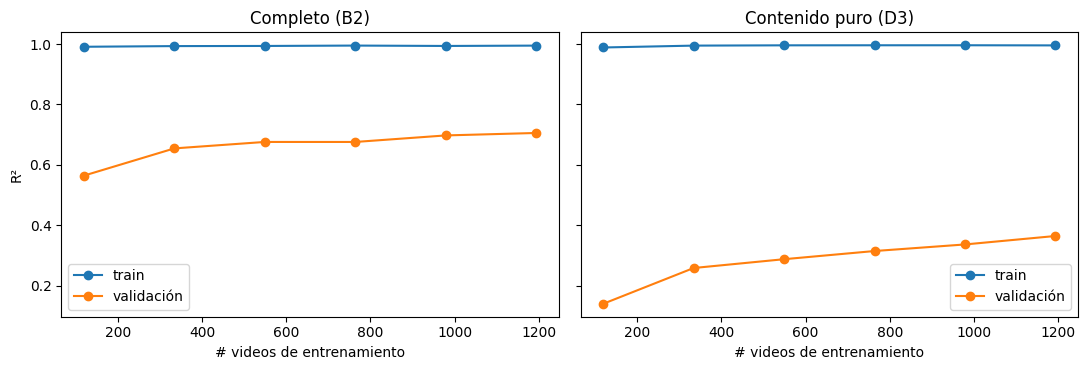

In [20]:
from sklearn.model_selection import GroupKFold, learning_curve
import matplotlib.pyplot as plt

grupos_kw = df.loc[X2_tr.index, "keyword"].astype(str).values
gkf = GroupKFold(5)
cfg = {k: M[k] for k in ["B2 meta+kw+emb+sent.transformer+idioma · HistGB",
                          "D1 B2 sin engagement ni antigüedad · HistGB",
                          "D3 contenido puro (emb+sent.) · HistGB",
                          "D5 [Av.II] solo TF-IDF · Ridge"]}
filas = []
for n, m in cfg.items():
    a = cross_validate(m, X2_tr, yr_tr, cv=cv, n_jobs=-1, scoring="r2")["test_score"].mean()
    b = cross_validate(m, X2_tr, yr_tr, cv=gkf, groups=grupos_kw, n_jobs=-1, scoring="r2")["test_score"].mean()
    filas.append({"modelo": n, "R2 (KFold, temas vistos)": a, "R2 (GroupKFold, temas NUEVOS)": b})
display(pd.DataFrame(filas).round(3))

# Curva de aprendizaje con particiones barajadas
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a_, (n, m) in zip(ax, [("Completo (B2)", cfg[list(cfg)[0]]), ("Contenido puro (D3)", cfg[list(cfg)[2]])]):
    sz, tr_, va_ = learning_curve(m, X2_tr, yr_tr, cv=cv, train_sizes=np.linspace(0.1, 1, 6), scoring="r2", n_jobs=-1)
    a_.plot(sz, tr_.mean(1), "o-", label="train"); a_.plot(sz, va_.mean(1), "o-", label="validación")
    a_.set_title(n); a_.set_xlabel("# videos de entrenamiento"); a_.legend()
ax[0].set_ylabel("R²"); plt.tight_layout(); plt.show()

In [21]:
import time, numpy as np
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV, cross_validate
from sklearn.ensemble import VotingRegressor, StackingRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from scipy.stats import loguniform, randint

# Los 384 embeddings se comprimen a 32 componentes DENTRO del pipeline (se ajusta solo con el entrenamiento de cada partición)
def prep3(logs=False, ncomp=32):
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_L if logs else NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
        ("emb", Pipeline([("sc", StandardScaler()), ("pca", PCA(ncomp, random_state=42))]), EMB),
        ("tr", StandardScaler(), TR + LANG)], sparse_threshold=0)

HGBf = lambda **k: HistGradientBoostingRegressor(random_state=42, early_stopping=True,
                                                 validation_fraction=0.15, n_iter_no_change=15, **k)

# 1) Búsqueda de hiperparámetros: 12 combinaciones × 3 particiones = 36 ajustes (antes 150)
base = Pipeline([("p", prep3()), ("m", HGBf(max_iter=300))])
espacio = {"m__learning_rate": loguniform(0.03, 0.2), "m__max_leaf_nodes": randint(6, 25),
           "m__min_samples_leaf": randint(10, 50), "m__l2_regularization": loguniform(1e-2, 10)}
t0 = time.time()
rs = RandomizedSearchCV(base, espacio, n_iter=12, cv=3, scoring="neg_root_mean_squared_error",
                        random_state=42, n_jobs=1)
rs.fit(X2_tr, yr_tr)
print(f"Búsqueda lista en {(time.time()-t0)/60:.1f} min | mejores hiperparámetros:", rs.best_params_)
hgb_t = rs.best_estimator_

# 2) Ensambles con modelos livianos
rf = Pipeline([("p", prep3()), ("m", RandomForestRegressor(150, max_depth=14, min_samples_leaf=3,
                                                           max_features=0.4, n_jobs=-1, random_state=42))])
rdg = Pipeline([("p", prep3(logs=True)), ("m", RidgeCV(alphas=np.logspace(-1, 3, 9)))])
vot = VotingRegressor([("hgb", hgb_t), ("rf", rf), ("ridge", rdg)], weights=[2, 1, 1])
stk = StackingRegressor([("hgb", hgb_t), ("rf", rf), ("ridge", rdg)], final_estimator=RidgeCV(), cv=3)

A0 = "A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB"
cands = {
    A0: M[A0],                                                                      # se reutiliza su resultado de la Celda 14
    "Av.III · HistGB sin afinar (PCA32)": Pipeline([("p", prep3()), ("m", HGBf(max_iter=300))]),
    "Av.III · HistGB afinado": hgb_t,
    "Av.III · Voting (HGB+RF+Ridge)": vot,
    "Av.III · Stacking": stk,
}

# 3) Comparación con la misma validación cruzada de 5 particiones de las celdas anteriores
filas = [res3[res3["modelo"] == A0][["modelo", "R2", "R2_std", "RMSE", "MAE"]].iloc[0].to_dict()]
for n, m in cands.items():
    if n == A0:
        continue
    t0 = time.time()
    r = cross_validate(m, X2_tr, yr_tr, cv=cv, n_jobs=1,
                       scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error"})
    filas.append({"modelo": n, "R2": r["test_r2"].mean(), "R2_std": r["test_r2"].std(),
                  "RMSE": -r["test_rmse"].mean(), "MAE": -r["test_mae"].mean()})
    print(f"listo: {n} ({time.time()-t0:.0f} s)")
res_iii = pd.DataFrame(filas).round(4)
res_iii["error_tipico"] = np.exp(res_iii["RMSE"]).round(2)
display(res_iii.sort_values("RMSE"))

Búsqueda lista en 0.5 min | mejores hiperparámetros: {'m__l2_regularization': np.float64(0.011166029133981346), 'm__learning_rate': np.float64(0.04648969488407204), 'm__max_leaf_nodes': 20, 'm__min_samples_leaf': 16}
listo: Av.III · HistGB sin afinar (PCA32) (6 s)
listo: Av.III · HistGB afinado (6 s)
listo: Av.III · Voting (HGB+RF+Ridge) (24 s)
listo: Av.III · Stacking (75 s)


,modelo,R2,R2_std,RMSE,MAE,error_tipico
4,Av.III · Stacking,0.7509,0.0295,1.2387,0.8882,3.45
3,Av.III · Voting (HGB+RF+Ridge),0.7435,0.0219,1.2575,0.9123,3.52
0,A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB,0.7219,0.0344,1.3071,0.9640,3.70
2,Av.III · HistGB afinado,0.7203,0.0218,1.3129,0.9612,3.72
1,Av.III · HistGB sin afinar (PCA32),0.7152,0.0248,1.3244,0.9658,3.76


In [22]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

elegido = res_iii.sort_values("RMSE").iloc[0]["modelo"]       # elegido por validación cruzada, no por prueba
print("Modelo elegido por CV:", elegido)

cands["Baseline"] = Pipeline([("p", prep2(kw=False)), ("m", DummyRegressor())])
preds, filas = {}, []
for n, m in cands.items():
    m.fit(X2_tr, yr_tr); p = m.predict(X2_te); preds[n] = p
    rm = mean_squared_error(yr_te, p) ** 0.5
    filas.append({"modelo": n, "R2": r2_score(yr_te, p), "RMSE": rm,
                  "MAE": mean_absolute_error(yr_te, p), "error_tipico": np.exp(rm)})
display(pd.DataFrame(filas).round(3))

# IC 95% bootstrap sobre el conjunto de prueba
rng = np.random.default_rng(42); y = yr_te.values; p, p0 = preds[elegido], preds[A0]
bs = []
for _ in range(2000):
    i = rng.integers(0, len(y), len(y))
    r_new = mean_squared_error(y[i], p[i]) ** 0.5; r_old = mean_squared_error(y[i], p0[i]) ** 0.5
    bs.append((r2_score(y[i], p[i]), r_new, r_old - r_new))
bs = np.array(bs)
print("IC95% R2 prueba      :", np.percentile(bs[:, 0], [2.5, 97.5]).round(3))
print("IC95% RMSE prueba    :", np.percentile(bs[:, 1], [2.5, 97.5]).round(3))
print("IC95% mejora de RMSE vs Av.II (positivo = mejor):", np.percentile(bs[:, 2], [2.5, 97.5]).round(3))

Modelo elegido por CV: Av.III · Stacking


,modelo,R2,RMSE,MAE,error_tipico
0,A0 [Av.II] SVD(TF-IDF)+meta+kw · HistGB,0.733,1.270,0.947,3.560
1,Av.III · HistGB sin afinar (PCA32),0.720,1.300,0.956,3.668
2,Av.III · HistGB afinado,0.741,1.249,0.934,3.486
3,Av.III · Voting (HGB+RF+Ridge),0.770,1.178,0.869,3.249
4,Av.III · Stacking,0.781,1.149,0.830,3.156
5,Baseline,-0.000,2.456,1.989,11.661


IC95% R2 prueba      : [0.703 0.839]
IC95% RMSE prueba    : [0.989 1.323]
IC95% mejora de RMSE vs Av.II (positivo = mejor): [0.051 0.184]


,modelo,accuracy,F1_macro,AUC
1,C1 meta+kw+emb+sent · HistGB,0.8587,0.8585,0.9349
0,A0 [Av.II] SVD+meta+kw · HistGB,0.8573,0.8573,0.9311
5,C5 Voting soft (C1+C2),0.8607,0.8606,0.9298
2,C2 meta+kw+emb+sent · LogReg,0.8346,0.8345,0.9069
3,C3 sin engagement/antigüedad · HistGB,0.7509,0.7508,0.8298
4,C4 contenido puro · LogReg,0.7160,0.7157,0.7839



=== C1 meta+kw+emb+sent · HistGB (PRUEBA) ===  AUC=0.935
              precision    recall  f1-score   support

           0       0.84      0.87      0.85       187
           1       0.86      0.84      0.85       187

    accuracy                           0.85       374
   macro avg       0.85      0.85      0.85       374
weighted avg       0.85      0.85      0.85       374


=== C4 contenido puro · LogReg (PRUEBA) ===  AUC=0.759
              precision    recall  f1-score   support

           0       0.71      0.65      0.68       187
           1       0.68      0.73      0.70       187

    accuracy                           0.69       374
   macro avg       0.69      0.69      0.69       374
weighted avg       0.69      0.69      0.69       374



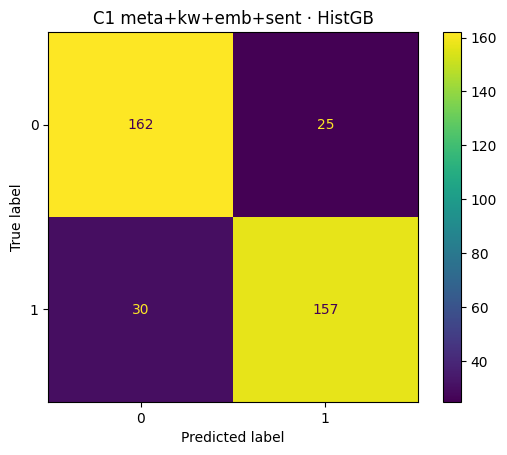

In [23]:
from sklearn.ensemble import HistGradientBoostingClassifier, VotingClassifier
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay
HGBc = lambda: HistGradientBoostingClassifier(random_state=42)

c1 = Pipeline([("p", prep2(emb=True, tr=True)), ("m", HGBc())])
c2 = Pipeline([("p", prep2(emb=True, tr=True, logs=True)), ("m", LogisticRegression(max_iter=3000, C=0.1))])
C = {
 "A0 [Av.II] SVD+meta+kw · HistGB":      Pipeline([("p", prep(True, True, 100)), ("m", HGBc())]),
 "C1 meta+kw+emb+sent · HistGB":         c1,
 "C2 meta+kw+emb+sent · LogReg":         c2,
 "C3 sin engagement/antigüedad · HistGB": Pipeline([("p", prep2(emb=True, tr=True, drop=NOENG)), ("m", HGBc())]),
 "C4 contenido puro · LogReg":           Pipeline([("p", prep2(meta=False, kw=False, emb=True, tr=True)), ("m", LogisticRegression(max_iter=3000, C=0.1))]),
 "C5 Voting soft (C1+C2)":               VotingClassifier([("hgb", c1), ("lr", c2)], voting="soft"),
}
filas = []
for n, m in C.items():
    r = cross_validate(m, X2_tr, yc_tr, cv=scv, n_jobs=-1, scoring=["accuracy", "f1_macro", "roc_auc"])
    filas.append({"modelo": n, "accuracy": r["test_accuracy"].mean(), "F1_macro": r["test_f1_macro"].mean(), "AUC": r["test_roc_auc"].mean()})
res_c = pd.DataFrame(filas).round(4); display(res_c.sort_values("AUC", ascending=False))

elegido_c = res_c.sort_values("AUC").iloc[-1]["modelo"]
for n in [elegido_c, "C4 contenido puro · LogReg"]:
    m = C[n].fit(X2_tr, yc_tr); pr = m.predict(X2_te)
    print(f"\n=== {n} (PRUEBA) ===  AUC={roc_auc_score(yc_te, m.predict_proba(X2_te)[:, 1]):.3f}")
    print(classification_report(yc_te, pr))
ConfusionMatrixDisplay.from_estimator(C[elegido_c], X2_te, yc_te); plt.title(elegido_c[:40]); plt.show()

,caida_R2,desv
"Otros metadatos (sentimiento léxico, longitudes, etc.)",-0.002,0.002
Sentimiento transformer + idioma,0.029,0.006
Embeddings de comentarios,0.060,0.009
Antigüedad,0.068,0.009
Keyword (tema),0.097,0.014
Likes medios de comentarios,0.106,0.014


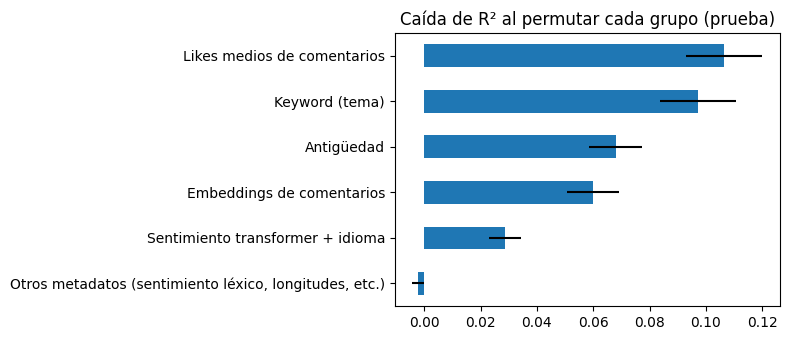

Keywords mejor predichas:
             mean  count
keyword                
finance     0.34      7
xbox        0.39     13
literature  0.40      4
cnn         0.42     10
how-to      0.46      9
news        0.48      8 

Keywords peor predichas:
                   mean  count
keyword                      
machine learning  1.09      9
data science      1.24      9
music             1.28     11
cubes             1.37      9
bed               1.51      7
movies            2.93     11


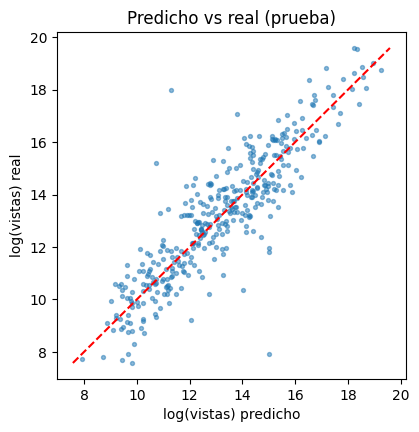

Modelo guardado: Av.III · Stacking


In [24]:
import joblib
modelo_final = cands[elegido]; pred = preds[elegido]

grupos = {"Likes medios de comentarios": ["mean_cl_likes"], "Antigüedad": ["age_days"],
          "Keyword (tema)": ["keyword"],
          "Otros metadatos (sentimiento léxico, longitudes, etc.)": [c for c in NUM if c not in ("mean_cl_likes", "age_days")],
          "Embeddings de comentarios": EMB, "Sentimiento transformer + idioma": TR + LANG}
base_r2 = r2_score(yr_te, modelo_final.predict(X2_te)); rng = np.random.default_rng(0); imp = {}
for g, cols in grupos.items():
    caidas = []
    for _ in range(10):
        Xp = X2_te.copy(); Xp[cols] = X2_te[cols].values[rng.permutation(len(Xp))]
        caidas.append(base_r2 - r2_score(yr_te, modelo_final.predict(Xp)))
    imp[g] = (np.mean(caidas), np.std(caidas))
imp = pd.DataFrame(imp, index=["caida_R2", "desv"]).T.sort_values("caida_R2"); display(imp.round(3))
imp["caida_R2"].plot.barh(xerr=imp["desv"], figsize=(8, 3.5), title="Caída de R² al permutar cada grupo (prueba)"); plt.tight_layout(); plt.show()

# Análisis de errores
rd = pd.DataFrame({"keyword": df.loc[X2_te.index, "keyword"].values, "y": yr_te.values, "pred": pred})
rd["abs_err"] = (rd["y"] - rd["pred"]).abs()
tab = rd.groupby("keyword")["abs_err"].agg(["mean", "count"]).sort_values("mean")
print("Keywords mejor predichas:\n", tab.head(6).round(2), "\n\nKeywords peor predichas:\n", tab.tail(6).round(2))
plt.figure(figsize=(4.5, 4.5)); plt.scatter(rd["pred"], rd["y"], s=8, alpha=.5)
lim = [rd[["y", "pred"]].min().min(), rd[["y", "pred"]].max().max()]; plt.plot(lim, lim, "r--")
plt.xlabel("log(vistas) predicho"); plt.ylabel("log(vistas) real"); plt.title("Predicho vs real (prueba)"); plt.show()

joblib.dump(modelo_final, "modelo_views.joblib")   # se usará en la API de la Semana 10
print("Modelo guardado:", elegido)

# Avances IV: celdas del proyecto Estadísticas de YouTube

## Resultados finales en el conjunto de prueba

In [25]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, accuracy_score, f1_score, roc_auc_score

def met(y, p):
    rm = mean_squared_error(y, p) ** 0.5
    return {"R2": r2_score(y, p), "RMSE": rm, "MAE": mean_absolute_error(y, p), "error_tipico": np.exp(rm)}

# Regresión: del baseline al modelo final
final_reg = pd.DataFrame({
    "Baseline (media)":               met(yr_te, preds["Baseline"]),
    "Avances II · Ridge TF-IDF":      met(yr_te, gs.predict(X_te)),
    "Avances II · HistGB":            met(yr_te, preds[A0]),
    "Avances III · Stacking (final)": met(yr_te, preds[elegido]),
}).T.round(3)
display(final_reg)

# Clasificación (alto/bajo): Avances II vs Avances III
c_av2, c_final = final, C[elegido_c]
def metc(m, X, y):
    return {"accuracy": accuracy_score(y, m.predict(X)), "F1_macro": f1_score(y, m.predict(X), average="macro"),
            "AUC": roc_auc_score(y, m.predict_proba(X)[:, 1])}
final_clf = pd.DataFrame({"Avances II · Reg. Logística": metc(c_av2, X_te, yc_te),
                          "Avances III · HistGB (final)": metc(c_final, X2_te, yc_te)}).T.round(3)
display(final_clf)

,R2,RMSE,MAE,error_tipico
Baseline (media),-0.000,2.456,1.989,11.661
Avances II · Ridge TF-IDF,0.562,1.625,1.271,5.080
Avances II · HistGB,0.733,1.270,0.947,3.560
Avances III · Stacking (final),0.781,1.149,0.830,3.156


,accuracy,F1_macro,AUC
Avances II · Reg. Logística,0.786,0.786,0.877
Avances III · HistGB (final),0.853,0.853,0.935


## Evolución de los resultados

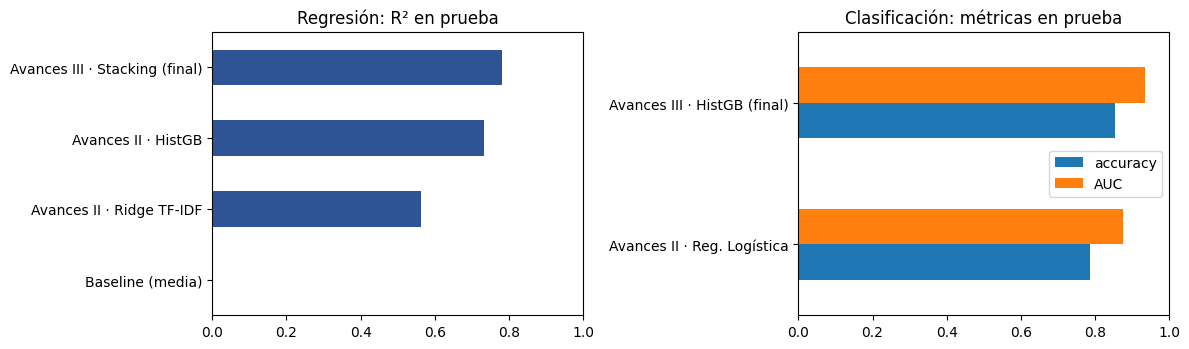

In [26]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
final_reg["R2"].plot.barh(ax=ax[0], color="#2F5496"); ax[0].set_title("Regresión: R² en prueba"); ax[0].set_xlim(0, 1)
final_clf[["accuracy", "AUC"]].plot.barh(ax=ax[1]); ax[1].set_title("Clasificación: métricas en prueba"); ax[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()

## Uso del modelo final con videos que no vio

In [27]:
margen = 1.28 * res_iii.loc[res_iii["modelo"] == elegido, "RMSE"].iloc[0]       # rango aproximado del 80 %

def estimar(i):
    idx = X2_te.index[i]; y_hat = preds[elegido][i]
    return {"video": str(df.loc[idx, "title"])[:45], "keyword": df.loc[idx, "keyword"],
            "vistas_reales": int(df.loc[idx, "views"]), "vistas_estimadas": int(np.expm1(y_hat)),
            "rango_80%": f"{int(np.expm1(y_hat - margen)):,} a {int(np.expm1(y_hat + margen)):,}",
            "prob_desempeno_alto": round(c_final.predict_proba(X2_te.iloc[[i]])[0, 1], 2)}

display(pd.DataFrame([estimar(i) for i in range(10)]))
print(f"Videos de prueba cuyo valor real cae dentro del rango del 80%: {np.mean(np.abs(yr_te.values - preds[elegido]) <= margen):.0%}")

,video,keyword,vistas_reales,vistas_estimadas,rango_80%,prob_desempeno_alto
0,How To Sell On Amazon As A Beginner Under 15,how-to,10671,9886,"2,024 a 48,268",0.00
1,Why Netflix is Now Making Video Games,gaming,176151,57055,"11,686 a 278,545",0.00
2,TOP 40 Songs of 2021 2022 \ Best English Song,music,20548194,4671289,"956,856 a 22,804,805",0.99
3,"Backwoods | FULL MOVIE | 2008 | Horror, Slash",movies,4043624,45494,"9,318 a 222,104",0.00
4,Introduction to Programming and Computer Scie,computer science,4849924,1590788,"325,853 a 7,766,088",0.99
5,DATA SCIENTIST CAREER STORY (how I became a d,data science,32054,70511,"14,442 a 344,233",0.01
6,Weird Things Spotted And Caught Deep Below On,google,2009963,1236791,"253,340 a 6,037,903",0.48
7,Reactions after Arsenal cruise past Bournemou,sports,65057,235956,"48,332 a 1,151,921",0.06
8,How To BRAINWASH Yourself For Success &amp; D,how-to,14322764,11437389,"2,342,810 a 55,836,277",1.00
9,Secret Rubik’s cube hiding spot 🤫 *Transformi,cubes,24994827,6454750,"1,322,177 a 31,511,498",1.00


Videos de prueba cuyo valor real cae dentro del rango del 80%: 89%
